In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
Clean_Data_Path = Path(r"D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\02_Clean_Data")
Table_Path = Path(r"D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables")
Chart_Path = Path(r"D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\charts")
Prediction_Path = Path(r"D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\predictions")

print("Clean data:", Clean_Data_Path)
print("Output tables:", Table_Path)
print("Output charts:", Chart_Path)
print("Output charts:", Prediction_Path)

Clean data: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\02_Clean_Data
Output tables: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables
Output charts: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\charts
Output charts: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\predictions


In [3]:
orders = pd.read_csv(
    Clean_Data_Path / "orders_clean.csv"
)

orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)

print("Orders:", orders.shape)
print(
    orders[
        [
            "order_id",
            "order_purchase_timestamp",
            "order_status"
        ]
    ].head()
)

Orders: (96461, 8)
                           order_id order_purchase_timestamp order_status
0  e481f51cbdc54678b7cc49136f2d6af7      2017-10-02 10:56:33    delivered
1  53cdb2fc8bc7dce0b6741e2150273451      2018-07-24 20:41:37    delivered
2  47770eb9100c2d0c44946d9cf07ec65d      2018-08-08 08:38:49    delivered
3  949d5b44dbf5de918fe9c16f97b45f8a      2017-11-18 19:28:06    delivered
4  ad21c59c0840e6cb83a9ceb5573f8159      2018-02-13 21:18:39    delivered


In [4]:
#For demand forecasting, we'll use number of orders per day.
daily_orders = (
    orders
    .dropna(subset=["order_purchase_timestamp"])
    .assign(
        purchase_date=lambda x:
            x["order_purchase_timestamp"].dt.normalize()
    )
    .groupby("purchase_date")
    .agg(
        order_count=("order_id", "nunique")
    )
    .reset_index()
)

daily_orders.head()

,purchase_date,order_count
0,2016-09-15,1
1,2016-10-03,8
2,2016-10-04,54
3,2016-10-05,35
4,2016-10-06,41


In [5]:
#Fill missing dates
full_date_range = pd.date_range(
    start=daily_orders["purchase_date"].min(),
    end=daily_orders["purchase_date"].max(),
    freq="D"
)

daily_orders = (
    daily_orders
    .set_index("purchase_date")
    .reindex(full_date_range)
    .rename_axis("purchase_date")
    .reset_index()
)

daily_orders["order_count"] = (
    daily_orders["order_count"]
    .fillna(0)
)

daily_orders.head()

,purchase_date,order_count
0,2016-09-15,1.0
1,2016-09-16,0.0
2,2016-09-17,0.0
3,2016-09-18,0.0
4,2016-09-19,0.0


In [6]:
#Check the demand timeline
print("Start date:", daily_orders["purchase_date"].min())
print("End date:", daily_orders["purchase_date"].max())
print("Number of days:", len(daily_orders))

print("\nMissing demand values:")
print(daily_orders["order_count"].isna().sum())

Start date: 2016-09-15 00:00:00
End date: 2018-08-29 00:00:00
Number of days: 714

Missing demand values:
0


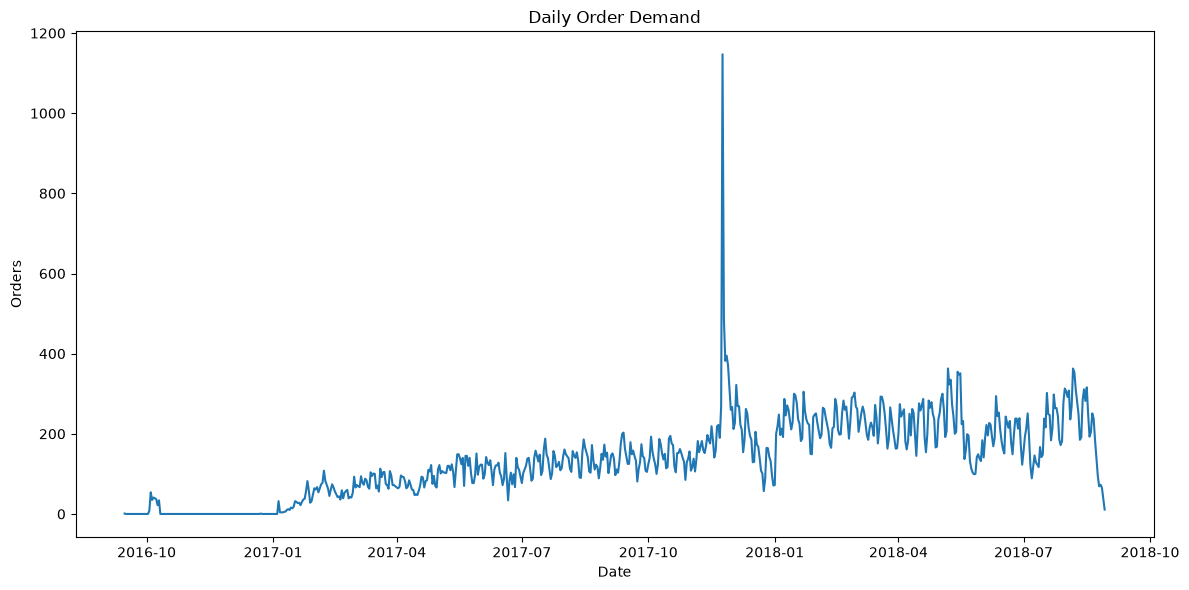

In [7]:
#Demand visualization
plt.figure(figsize=(12, 6))

plt.plot(
    daily_orders["purchase_date"],
    daily_orders["order_count"]
)

plt.title("Daily Order Demand")
plt.xlabel("Date")
plt.ylabel("Orders")

plt.tight_layout()

plt.savefig(
    Chart_Path / "23_daily_order_demand.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
#forecasting features
forecast_data = daily_orders.copy()

forecast_data["day_of_week"] = (
    forecast_data["purchase_date"].dt.dayofweek
)

forecast_data["month"] = (
    forecast_data["purchase_date"].dt.month
)

forecast_data["day_of_month"] = (
    forecast_data["purchase_date"].dt.day
)

forecast_data["week_of_year"] = (
    forecast_data["purchase_date"].dt.isocalendar().week.astype(int)
)

forecast_data["trend"] = (
    np.arange(len(forecast_data))
)

In [10]:
#Lag features
lag_days = [1, 7, 14, 28]

for lag in lag_days:
    forecast_data[f"lag_{lag}"] = (
        forecast_data["order_count"].shift(lag)
    )

In [11]:
#Rolling features
forecast_data["rolling_7_mean"] = (
    forecast_data["order_count"]
    .shift(1)
    .rolling(window=7)
    .mean()
)

forecast_data["rolling_28_mean"] = (
    forecast_data["order_count"]
    .shift(1)
    .rolling(window=28)
    .mean()
)

In [12]:
#Remove rows without enough history
forecast_data = forecast_data.dropna().reset_index(drop=True)

print(
    "Forecasting rows:",
    len(forecast_data)
)

forecast_data.head()

Forecasting rows: 686


,purchase_date,order_count,day_of_week,month,day_of_month,week_of_year,trend,lag_1,lag_7,lag_14,lag_28,rolling_7_mean,rolling_28_mean
0,2016-10-13,0.0,3,10,13,41,28,0.0,41.0,0.0,1.0,24.714286,9.678571
1,2016-10-14,0.0,4,10,14,41,29,0.0,39.0,0.0,0.0,18.857143,9.642857
2,2016-10-15,0.0,5,10,15,41,30,0.0,37.0,0.0,0.0,13.285714,9.642857
3,2016-10-16,0.0,6,10,16,41,31,0.0,22.0,0.0,0.0,8.000000,9.642857
4,2016-10-17,0.0,0,10,17,42,32,0.0,34.0,8.0,0.0,4.857143,9.642857


In [13]:
#Defining features and target
feature_columns = [
    "day_of_week",
    "month",
    "day_of_month",
    "week_of_year",
    "trend",
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_7_mean",
    "rolling_28_mean"
]

X = forecast_data[feature_columns]

y = forecast_data["order_count"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (686, 11)
Target: (686,)


In [14]:
#Time-based train/test split
test_days = 30

split_index = len(forecast_data) - test_days

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

test_dates = forecast_data["purchase_date"].iloc[split_index:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print(
    "Test period:",
    test_dates.min(),
    "to",
    test_dates.max()
)

Training rows: 656
Testing rows: 30
Test period: 2018-07-31 00:00:00 to 2018-08-29 00:00:00


In [15]:
#Baseline model we will use Same weekday last week
baseline_predictions = forecast_data[
    "lag_7"
].iloc[split_index:].values

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_predictions
    )
)

baseline_mape = (
    np.mean(
        np.abs(
            (y_test.values - baseline_predictions)
            / np.where(
                y_test.values == 0,
                1,
                y_test.values
            )
        )
    )
    * 100
)

print("Baseline MAE:", round(baseline_mae, 2))
print("Baseline RMSE:", round(baseline_rmse, 2))
print("Baseline MAPE:", round(baseline_mape, 2), "%")

Baseline MAE: 76.33
Baseline RMSE: 94.98
Baseline MAPE: 115.34 %


In [16]:
#Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max

In [17]:
#Generate test predictions
rf_predictions = rf_model.predict(
    X_test
)

rf_predictions = np.maximum(
    rf_predictions,
    0
)

rf_predictions[:10]

array([257.64351124, 280.27119974, 260.21151058, 262.69752513,
       249.09559259, 186.74714947, 279.79118386, 349.1484032 ,
       318.52243056, 270.85897517])

In [18]:
#Evaluating Random Forest
rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_predictions
    )
)

rf_mape = (
    np.mean(
        np.abs(
            (y_test.values - rf_predictions)
            / np.where(
                y_test.values == 0,
                1,
                y_test.values
            )
        )
    )
    * 100
)

print("Random Forest MAE:", round(rf_mae, 2))
print("Random Forest RMSE:", round(rf_rmse, 2))
print("Random Forest MAPE:", round(rf_mape, 2), "%")

Random Forest MAE: 37.35
Random Forest RMSE: 46.29
Random Forest MAPE: 52.11 %


In [19]:
#Model comparison
model_comparison = pd.DataFrame({
    "model": [
        "Seasonal Naive Baseline",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        rf_rmse
    ],
    "MAPE_percent": [
        baseline_mape,
        rf_mape
    ]
})

model_comparison

,model,MAE,RMSE,MAPE_percent
0,Seasonal Naive Baseline,76.333333,94.980349,115.339211
1,Random Forest,37.352392,46.287261,52.112234


In [20]:
model_comparison.to_csv(
    Table_Path / "demand_model_comparison.csv",
    index=False
)

print(
    "Saved:",
    Table_Path / "demand_model_comparison.csv"
)

Saved: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables\demand_model_comparison.csv


In [21]:
#Actual vs predicted demand
test_predictions = pd.DataFrame({
    "date": test_dates.values,
    "actual_orders": y_test.values,
    "baseline_prediction": baseline_predictions,
    "random_forest_prediction": rf_predictions
})

test_predictions.head()

,date,actual_orders,baseline_prediction,random_forest_prediction
0,2018-07-31,313.0,264.0,257.643511
1,2018-08-01,306.0,264.0,280.271200
2,2018-08-02,292.0,244.0,260.211511
3,2018-08-03,308.0,186.0,262.697525
4,2018-08-04,236.0,172.0,249.095593


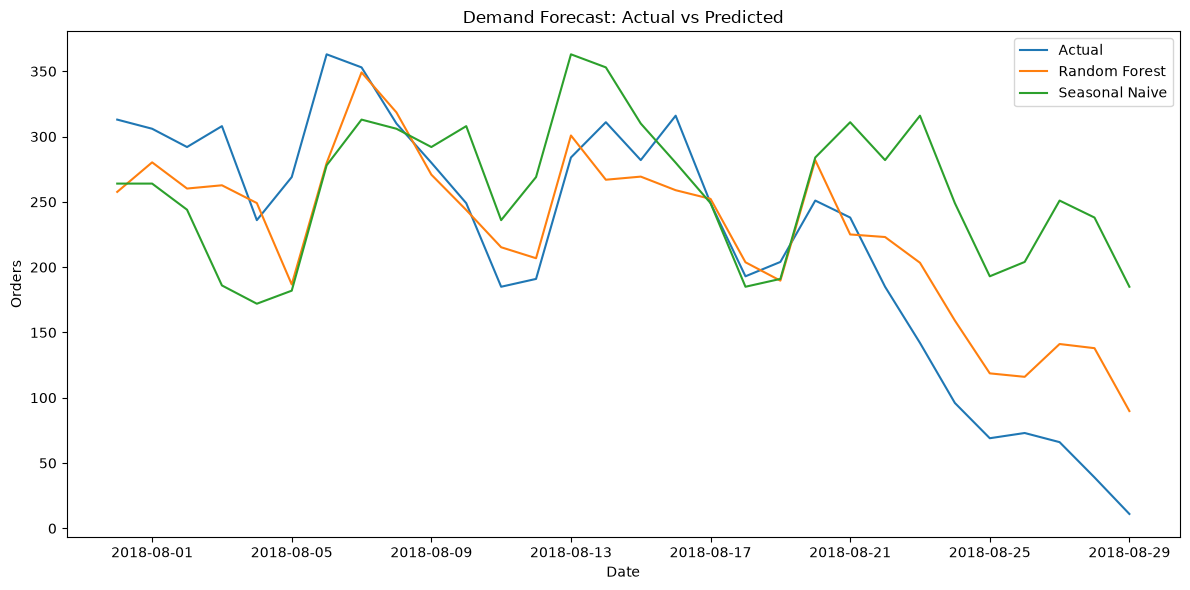

In [22]:
#Visualization
plt.figure(figsize=(12, 6))

plt.plot(
    test_predictions["date"],
    test_predictions["actual_orders"],
    label="Actual"
)

plt.plot(
    test_predictions["date"],
    test_predictions["random_forest_prediction"],
    label="Random Forest"
)

plt.plot(
    test_predictions["date"],
    test_predictions["baseline_prediction"],
    label="Seasonal Naive"
)

plt.title("Demand Forecast: Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Orders")
plt.legend()

plt.tight_layout()

plt.savefig(
    Chart_Path / "24_demand_forecast_evaluation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
#Feature importance
feature_importance = pd.DataFrame({
    "feature": feature_columns,
    "importance": rf_model.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

feature_importance

,feature,importance
5,lag_1,0.607282
4,trend,0.134414
9,rolling_7_mean,0.117422
6,lag_7,0.067508
0,day_of_week,0.023280
8,lag_28,0.014239
7,lag_14,0.012815
10,rolling_28_mean,0.010595
2,day_of_month,0.005785
3,week_of_year,0.005124


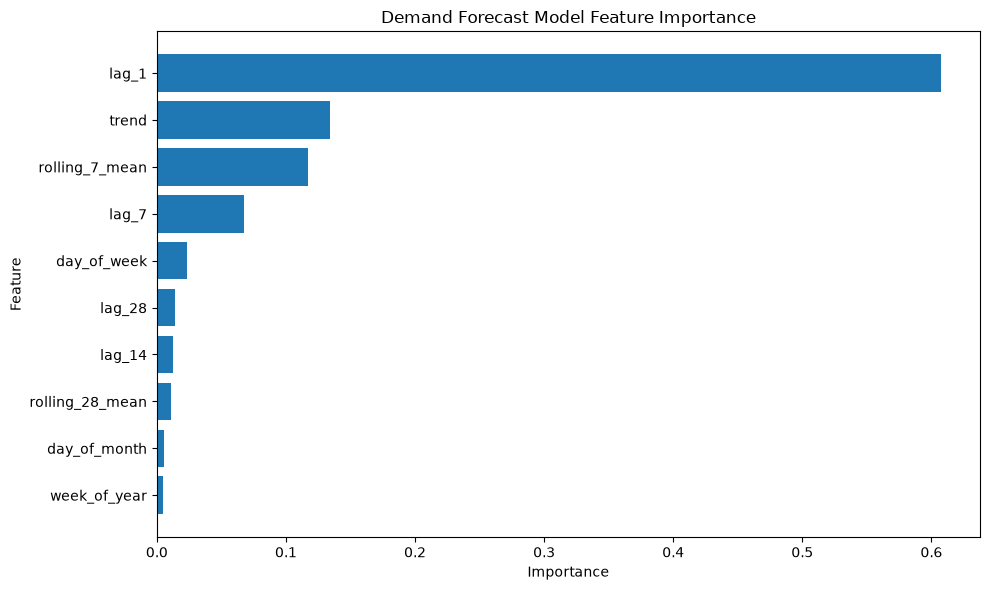

In [24]:
#Feature importance chart
top_features = (
    feature_importance
    .head(10)
    .sort_values("importance")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.title("Demand Forecast Model Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig(
    Chart_Path / "25_demand_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [25]:
#Trainning final model
final_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

final_model.fit(
    X,
    y
)

print("Final demand model trained.")

Final demand model trained.


In [26]:
#Creating 30-day future forecast
history = daily_orders[
    ["purchase_date", "order_count"]
].copy()

future_predictions = []

last_date = history["purchase_date"].max()

for i in range(1, 31):

    future_date = (
        last_date
        + pd.Timedelta(days=i)
    )

    temp_history = pd.concat(
        [
            history,
            pd.DataFrame({
                "purchase_date": [future_date],
                "order_count": [np.nan]
            })
        ],
        ignore_index=True
    )

    temp_history["day_of_week"] = (
        temp_history["purchase_date"].dt.dayofweek
    )

    temp_history["month"] = (
        temp_history["purchase_date"].dt.month
    )

    temp_history["day_of_month"] = (
        temp_history["purchase_date"].dt.day
    )

    temp_history["week_of_year"] = (
        temp_history["purchase_date"]
        .dt.isocalendar()
        .week
        .astype(int)
    )

    temp_history["trend"] = (
        np.arange(len(temp_history))
    )

    temp_history["lag_1"] = (
        temp_history["order_count"].shift(1)
    )

    temp_history["lag_7"] = (
        temp_history["order_count"].shift(7)
    )

    temp_history["lag_14"] = (
        temp_history["order_count"].shift(14)
    )

    temp_history["lag_28"] = (
        temp_history["order_count"].shift(28)
    )

    temp_history["rolling_7_mean"] = (
        temp_history["order_count"]
        .shift(1)
        .rolling(7)
        .mean()
    )

    temp_history["rolling_28_mean"] = (
        temp_history["order_count"]
        .shift(1)
        .rolling(28)
        .mean()
    )

    future_row = temp_history.iloc[-1]

    X_future = future_row[
        feature_columns
    ].to_frame().T

    prediction = final_model.predict(
        X_future
    )[0]

    prediction = max(
        0,
        prediction
    )

    future_predictions.append({
        "date": future_date,
        "predicted_orders": prediction
    })

    history.loc[len(history)] = [
        future_date,
        prediction
    ]

In [27]:
#Forecast table
future_forecast = pd.DataFrame(
    future_predictions
)

future_forecast["predicted_orders"] = (
    future_forecast["predicted_orders"]
    .round(0)
    .astype(int)
)

future_forecast

,date,predicted_orders
0,2018-08-30,44
1,2018-08-31,50
2,2018-09-01,60
3,2018-09-02,79
4,2018-09-03,101
5,2018-09-04,109
6,2018-09-05,115
7,2018-09-06,117
8,2018-09-07,110
9,2018-09-08,95


In [28]:
future_forecast.to_csv(
    Prediction_Path / "30_day_demand_forecast.csv",
    index=False
)

print(
    "Saved:",
    Prediction_Path / "30_day_demand_forecast.csv"
)

Saved: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\predictions\30_day_demand_forecast.csv


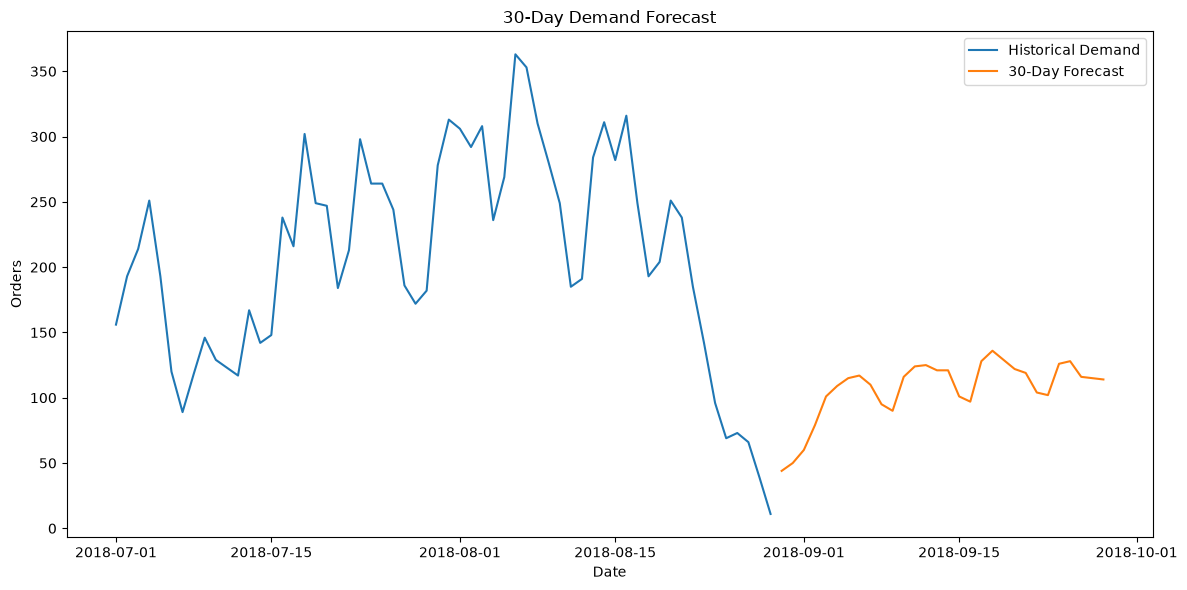

In [29]:
#Forecast visualization
recent_history = daily_orders.tail(60)

plt.figure(figsize=(12, 6))

plt.plot(
    recent_history["purchase_date"],
    recent_history["order_count"],
    label="Historical Demand"
)

plt.plot(
    future_forecast["date"],
    future_forecast["predicted_orders"],
    label="30-Day Forecast"
)

plt.title("30-Day Demand Forecast")
plt.xlabel("Date")
plt.ylabel("Orders")
plt.legend()

plt.tight_layout()

plt.savefig(
    Chart_Path / "26_30_day_demand_forecast.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [30]:
#Forecast summary
forecast_summary = pd.DataFrame({
    "metric": [
        "Forecast Horizon",
        "Total Forecasted Orders",
        "Average Daily Forecast",
        "Minimum Daily Forecast",
        "Maximum Daily Forecast"
    ],
    "value": [
        "30 days",
        future_forecast["predicted_orders"].sum(),
        round(
            future_forecast["predicted_orders"].mean(),
            2
        ),
        future_forecast["predicted_orders"].min(),
        future_forecast["predicted_orders"].max()
    ]
})

forecast_summary

,metric,value
0,Forecast Horizon,30 days
1,Total Forecasted Orders,3214
2,Average Daily Forecast,107.13
3,Minimum Daily Forecast,44
4,Maximum Daily Forecast,136


In [31]:
forecast_summary.to_csv(
    Table_Path / "demand_forecast_summary.csv",
    index=False
)

print(
    "Saved:",
    Table_Path / "demand_forecast_summary.csv"
)

Saved: D:\Projects\Smart_E-Commerce_Demand_&_Operations_Intelligence_System\09_Outputs\tables\demand_forecast_summary.csv
